<a href="https://colab.research.google.com/github/ganapriyahs/learn_ml_with_me/blob/main/Deep_Q_learning_lunar_lander.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Q-Learning = Learning to act from rewards (Lunar Lander)
#### In this file I walk through **reinforcement learning (RL)** and the **Deep Q-Network (DQN)** algorithm.

Everything before this had a dataset of (input, correct answer) pairs. In RL there are **no correct answers**. An *agent* acts in an *environment*, sees a new *state*, and receives a *reward* - and has to figure out for itself which actions lead to the most reward over time.

| word | meaning in Lunar Lander |
|---|---|
| state $s$ | position, velocity, angle, leg contact of the lander |
| action $a$ | do nothing / fire left / fire main / fire right engine |
| reward $R$ | +100 or so for a soft landing, -100 for a crash, small penalties for burning fuel |
| return | the (discounted) sum of all future rewards: $R_1 + \gamma R_2 + \gamma^2 R_3 + \dots$ |

**The Q-function** $Q(s,a)$ = the return I would get if I take action $a$ in state $s$ and play optimally afterwards. If I knew Q, the policy is trivial: *always pick the action with the largest Q*.

The notebook has two parts:
- **Part 1** (runs anywhere): the full DQN algorithm in NumPy on a small landing game I can simulate myself - so I can see it learn in seconds.
- **Part 2** (needs Colab): the same algorithm on the real `LunarLander` with TensorFlow, as in the course lab.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

## The Bellman equation - the heart of Q-learning
The value of $(s,a)$ = the immediate reward + the discounted value of the best thing I can do next:

$$Q(s,a) = R(s) + \gamma \max_{a'} Q(s', a')$$

$\gamma$ (e.g. 0.99) is the **discount factor**: a reward now is worth a bit more than the same reward later.

For a huge state space I can't keep a table, so I use a **neural network** $Q(s,a;w)$ that takes the state and outputs one Q-value per action. Training it is supervised learning with a *moving target*:

$$y = R + \gamma \max_{a'} \hat Q(s', a'; w^-) \qquad \text{loss} = (y - Q(s,a;w))^2$$

(if $s'$ ends the episode there is no future, so $y = R$).

Two tricks make this stable - without them DQN often diverges:
1. **Target network** $\hat Q$ with weights $w^-$: a slowly-updated copy of the Q-network. Without it the target moves every time I update, like chasing my own tail. I use a *soft update*: $w^- \leftarrow \tau w + (1-\tau)w^-$ with a small $\tau$.
2. **Experience replay**: store transitions $(s,a,r,s',done)$ in a memory buffer and train on **random mini-batches** from it. Consecutive frames are very correlated; random sampling breaks that, and each experience gets reused many times.

And to explore I use **$\epsilon$-greedy**: with probability $\epsilon$ take a random action, otherwise the greedy one; $\epsilon$ starts at 1 and decays towards a small minimum.

# Part 1 - DQN from scratch in NumPy

## A small environment I can run anywhere: `SoftLanding`
The real Lunar Lander needs a physics engine (Box2D). So that I can run DQN end-to-end here, I made a tiny 1-D version of the same problem:

- The lander starts 8-10 units above the ground with zero velocity. **State** = `(height, velocity)`.
- Each step I choose **action 0** (engines off: gravity pulls down, velocity -= 0.4) or **action 1** (fire thruster: velocity += 0.4, costs -0.3 reward).
- Touching the ground at speed <= 1.0 -> **+100** (soft landing). Faster -> **-100** (crash). Flying off above 20, or running past 60 steps -> **-100**.

The agent must learn *when* to start braking: too early wastes fuel or sends it flying away, too late crashes it.

In [2]:
class SoftLanding:
    def __init__(self, seed=0):
        self.rng = np.random.default_rng(seed)
    def reset(self):
        self.h = self.rng.uniform(8, 10); self.v = 0.0; self.t = 0
        return self._obs()
    def _obs(self):
        return np.array([self.h / 10, self.v / 5], dtype=np.float32)       # scaled to roughly [-1, 1]
    def step(self, a):
        self.t += 1
        self.v += 0.4 if a == 1 else -0.4
        self.h += self.v
        r = -0.3 if a == 1 else 0.0                                         # fuel cost
        if self.h <= 0:                                                     # touched the ground
            return self._obs(), r + (100.0 if self.v >= -1.0 else -100.0), True
        if self.h > 20 or self.t >= 60:                                     # flew away / ran out of time
            return self._obs(), r - 100.0, True
        return self._obs(), r, False

# what happens if the agent never fires the thruster?
env = SoftLanding(0); s = env.reset(); done = False
while not done:
    s, r, done = env.step(0)
print("never thrusting -> final reward:", r, "| impact speed:", round(env.v, 2))

never thrusting -> final reward: -100.0 | impact speed: -2.8


## The Q-network
A small fully connected network `2 -> 64 -> 64 -> 2` (two ReLU hidden layers, one linear Q-value per action). I hand-write the forward and backward pass, as in the previous notebooks.

In [3]:
class QNet:
    def __init__(self, sizes, seed):
        r = np.random.default_rng(seed)
        self.L = len(sizes) - 1
        self.p = {}
        for l in range(self.L):
            self.p[f"W{l}"] = r.normal(0, np.sqrt(2 / sizes[l]), (sizes[l], sizes[l + 1]))
            self.p[f"b{l}"] = np.zeros(sizes[l + 1])

    def forward(self, X, keep=False):
        acts, pre = [X], []
        for l in range(self.L):
            z = acts[-1] @ self.p[f"W{l}"] + self.p[f"b{l}"]
            pre.append(z)
            acts.append(np.maximum(z, 0) if l < self.L - 1 else z)            # ReLU, but linear output layer
        if keep: self.acts, self.pre = acts, pre
        return acts[-1]

    def backward(self, dout):
        g, d = {}, dout
        for l in reversed(range(self.L)):
            g[f"W{l}"] = self.acts[l].T @ d; g[f"b{l}"] = d.sum(0)
            if l > 0: d = (d @ self.p[f"W{l}"].T) * (self.pre[l - 1] > 0)
        return g

    def soft_update_from(self, other, tau):                                    # w_target <- tau*w + (1-tau)*w_target
        for k in self.p:
            self.p[k] = tau * other.p[k] + (1 - tau) * self.p[k]

## The learning step
This is the exact logic of the lab's `compute_loss` + `agent_learn`:
1. Sample a mini-batch of experiences.
2. Targets: `y = R + gamma * max_a' Q_target(s', a') * (1 - done)`.
3. The loss only involves the Q-value of the action that was **actually taken** - so the gradient is zero for the other output.
4. One Adam step on the Q-network, then a soft update of the target network.

In [4]:
def adam_step(net, grads, m, v, t, lr):
    for k in net.p:
        m[k] = 0.9 * m[k] + 0.1 * grads[k]; v[k] = 0.999 * v[k] + 0.001 * grads[k] ** 2
        net.p[k] -= lr * (m[k] / (1 - 0.9 ** t)) / (np.sqrt(v[k] / (1 - 0.999 ** t)) + 1e-8)

def agent_learn(batch, gamma, q_net, target_net, opt):
    S, A, R, S2, D = batch
    y = R + gamma * target_net.forward(S2).max(axis=1) * (1 - D)               # Bellman targets
    out = q_net.forward(S, keep=True)
    n = len(A)
    dout = np.zeros_like(out)
    dout[np.arange(n), A] = 2 * (out[np.arange(n), A] - y) / n                  # d(MSE)/d(Q of the taken action)
    opt["t"] += 1
    adam_step(q_net, q_net.backward(dout), opt["m"], opt["v"], opt["t"], opt["lr"])
    target_net.soft_update_from(q_net, opt["tau"])
    return np.mean((out[np.arange(n), A] - y) ** 2)

## Hyperparameters
Same names as the lab. The numbers are different because my game is much simpler than Lunar Lander (I use a bigger `TAU` so the tiny target network follows along fast enough).

In [5]:
MEMORY_SIZE = 50_000       # replay buffer capacity
GAMMA = 0.99               # discount factor
ALPHA = 1e-3               # learning rate
TAU = 0.01                 # soft-update rate of the target network
MINIBATCH_SIZE = 64
NUM_STEPS_FOR_UPDATE = 4   # learn every 4 environment steps
E_DECAY, E_MIN = 0.99, 0.01
NUM_EPISODES = 1000

## The training loop
```
for each episode:
    state = env.reset()
    while not done:
        action = epsilon-greedy(Q(state))
        next_state, reward, done = env.step(action)
        memory.append((state, action, reward, next_state, done))
        every 4 steps (and when memory has a full mini-batch): sample a batch, learn
    decay epsilon
```

In [6]:
def train_dqn(seed=0, episodes=NUM_EPISODES, verbose=True):
    env, rng = SoftLanding(seed), np.random.default_rng(seed)
    q_net, target_net = QNet([2, 64, 64, 2], seed), QNet([2, 64, 64, 2], seed + 1)
    target_net.soft_update_from(q_net, 1.0)                                       # tau = 1 -> start as an exact copy
    opt = {"m": {k: np.zeros_like(v) for k, v in q_net.p.items()}, "v": {k: np.zeros_like(v) for k, v in q_net.p.items()},
           "t": 0, "lr": ALPHA, "tau": TAU}
    memory, eps, steps, returns = deque(maxlen=MEMORY_SIZE), 1.0, 0, []

    for ep in range(episodes):
        s, done, total = env.reset(), False, 0.0
        while not done:
            a = int(rng.integers(2)) if rng.random() < eps else int(np.argmax(q_net.forward(s[None])[0]))
            s2, r, done = env.step(a)
            memory.append((s, a, r, s2, done)); s = s2; total += r; steps += 1
            if steps % NUM_STEPS_FOR_UPDATE == 0 and len(memory) >= MINIBATCH_SIZE:
                idx = rng.choice(len(memory), MINIBATCH_SIZE, replace=False)
                b = [memory[i] for i in idx]
                batch = (np.array([x[0] for x in b]), np.array([x[1] for x in b]), np.array([x[2] for x in b]),
                         np.array([x[3] for x in b]), np.array([x[4] for x in b], dtype=float))
                agent_learn(batch, GAMMA, q_net, target_net, opt)
        eps = max(E_MIN, eps * E_DECAY)
        returns.append(total)
        if verbose and (ep % 100 == 0 or ep == episodes - 1):
            print(f"episode {ep:4d} | average return of last 50: {np.mean(returns[-50:]):7.1f} | epsilon {eps:.3f}")
    return q_net, returns

q_net, returns = train_dqn(seed=0)

episode    0 | average return of last 50:  -104.8 | epsilon 0.990
episode  100 | average return of last 50:   -37.8 | epsilon 0.362
episode  200 | average return of last 50:    30.1 | epsilon 0.133
episode  300 | average return of last 50:    47.0 | epsilon 0.049
episode  400 | average return of last 50:     7.2 | epsilon 0.018
episode  500 | average return of last 50:    19.2 | epsilon 0.010
episode  600 | average return of last 50:     3.2 | epsilon 0.010
episode  700 | average return of last 50:    15.1 | epsilon 0.010
episode  800 | average return of last 50:    97.8 | epsilon 0.010
episode  900 | average return of last 50:    97.2 | epsilon 0.010
episode  999 | average return of last 50:    96.9 | epsilon 0.010


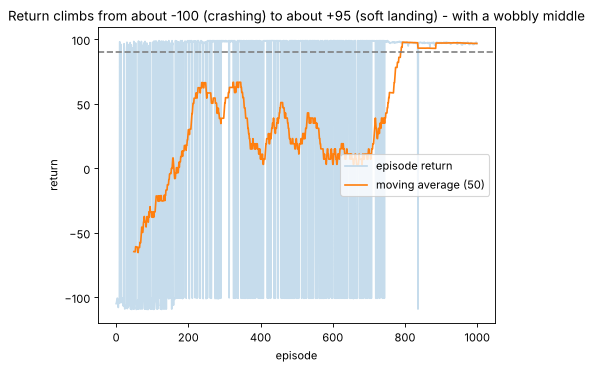

In [7]:
avg = np.convolve(returns, np.ones(50) / 50, mode="valid")
plt.plot(returns, alpha=0.25, label="episode return"); plt.plot(range(49, len(returns)), avg, label="moving average (50)")
plt.axhline(90, ls="--", c="grey"); plt.xlabel("episode"); plt.ylabel("return"); plt.legend()
plt.title("Return climbs from about -100 (crashing) to about +95 (soft landing) - with a wobbly middle"); plt.show()

## Watching the trained agent
Switch off exploration ($\epsilon = 0$) and let it play 300 fresh games.

soft-landing success rate (greedy policy): 100%


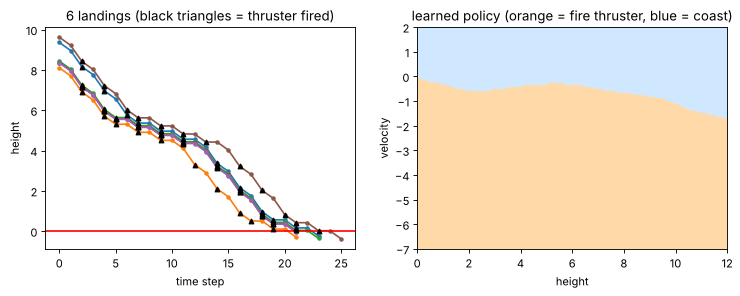

In [8]:
def play(q_net, n=300, seed=123, trace=False):
    env, wins, traces = SoftLanding(seed), 0, []
    for _ in range(n):
        s, done, hs, acts = env.reset(), False, [env.h], []
        while not done:
            a = int(np.argmax(q_net.forward(s[None])[0]))
            s, r, done = env.step(a); hs.append(env.h); acts.append(a)
        wins += r > 50
        traces.append((hs, acts, env.v))
    return wins / n, traces

rate, traces = play(q_net)
print(f"soft-landing success rate (greedy policy): {rate:.0%}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for hs, acts, vend in traces[:6]:
    ax[0].plot(hs, "-o", ms=3)
    ax[0].scatter([i for i, a in enumerate(acts) if a == 1], [hs[i] for i, a in enumerate(acts) if a == 1], marker="^", c="k", s=18, zorder=5)
ax[0].axhline(0, c="r"); ax[0].set_xlabel("time step"); ax[0].set_ylabel("height"); ax[0].set_title("6 landings (black triangles = thruster fired)")
# the learned policy: where does it choose to fire?
H, V = np.meshgrid(np.linspace(0, 12, 120), np.linspace(-7, 2, 120))
Q = q_net.forward(np.stack([H.ravel() / 10, V.ravel() / 5], 1))
ax[1].contourf(H, V, (Q[:, 1] > Q[:, 0]).reshape(H.shape), levels=[-.5, .5, 1.5], colors=["#cfe8ff", "#ffd9a8"])
ax[1].set_xlabel("height"); ax[1].set_ylabel("velocity"); ax[1].set_title("learned policy (orange = fire thruster, blue = coast)")
plt.show()

The right plot is the nicest result. The agent learned a **speed limit that gets stricter as it gets closer to the ground**: high up it tolerates falling at roughly 1.5-2 units per step, but near the ground the orange region reaches almost zero velocity, so it slows to a gentle touchdown. Nobody told it that; it only ever saw rewards.

## RL is unstable: same code, different random seeds
I got a good result with seed 0. Running other seeds is a reality check - RL training is much more sensitive to randomness than supervised learning.

In [9]:
for seed in [0, 1, 2]:
    qn, rets = train_dqn(seed=seed, verbose=False)
    print(f"seed {seed}: soft-landing success {play(qn)[0]:.0%} | average return over last 100 training episodes {np.mean(rets[-100:]):.1f}")

seed 0: soft-landing success 100% | average return over last 100 training episodes 97.2
seed 1: soft-landing success 100% | average return over last 100 training episodes 90.9
seed 2: soft-landing success 100% | average return over last 100 training episodes -100.8


Seed 2 gets stuck near -100: its policy never learns to land (it keeps crashing or flying away). That is normal for DQN, not a bug in the notebook. Typical remedies: more exploration, a slower epsilon decay, a lower learning rate, a bigger replay buffer, or reward shaping.

---
# Part 2 - The real Lunar Lander with TensorFlow
This is the course lab's setup. **I could not run any of the cells below where I prepared this notebook** (no TensorFlow, no Box2D, no internet) - so run them in Google Colab. The first cell installs the environment; the training loop takes a while (the lab reports it can take ~15-20 minutes on a CPU runtime).

**The environment**: 8 state numbers (x, y, vx, vy, angle, angular velocity, left-leg contact, right-leg contact), 4 actions (0 do nothing, 1 fire left engine, 2 fire main engine, 3 fire right engine). Roughly: +100 to +140 for landing on the pad, -100 for crashing, +10 per leg touching the ground, -0.3 per frame the main engine fires. An episode is "solved" at **200 points** on average. 

In [ ]:
!pip install -q "gymnasium[box2d]"

In [ ]:
import random
import numpy as np
import tensorflow as tf
import gymnasium as gym
from collections import deque
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

env = gym.make("LunarLander-v3")             # on an older gymnasium use "LunarLander-v2"
state_size = env.observation_space.shape     # (8,)
num_actions = env.action_space.n             # 4
print("State size:", state_size, "| actions:", num_actions)

MEMORY_SIZE, GAMMA, ALPHA, TAU = 100_000, 0.995, 1e-3, 1e-3
MINIBATCH_SIZE, NUM_STEPS_FOR_UPDATE = 64, 4
E_DECAY, E_MIN = 0.995, 0.01

## Q-network and target network
The lab uses 2 hidden layers of 64 ReLU units and one linear output per action - the same shape as my NumPy network, only with 8 inputs and 4 outputs. The target network is a second copy with the same architecture.

In [ ]:
q_network = Sequential([Input(shape=state_size),
                        Dense(64, activation="relu"), Dense(64, activation="relu"),
                        Dense(num_actions, activation="linear")])
target_q_network = Sequential([Input(shape=state_size),
                               Dense(64, activation="relu"), Dense(64, activation="relu"),
                               Dense(num_actions, activation="linear")])
optimizer = Adam(learning_rate=ALPHA)
target_q_network.set_weights(q_network.get_weights())

## Loss: the Bellman error on the action actually taken
`tf.gather_nd` picks, for every example in the batch, the Q-value of the action that was taken - same idea as `out[np.arange(n), A]` in my NumPy version.

In [ ]:
def compute_loss(experiences, gamma, q_network, target_q_network):
    states, actions, rewards, next_states, done_vals = experiences
    max_qsa = tf.reduce_max(target_q_network(next_states), axis=-1)
    y_targets = rewards + gamma * max_qsa * (1 - done_vals)
    q_values = q_network(states)
    q_values = tf.gather_nd(q_values, tf.stack([tf.range(q_values.shape[0]), tf.cast(actions, tf.int32)], axis=1))
    return tf.keras.losses.MSE(y_targets, q_values)

@tf.function
def agent_learn(experiences, gamma):
    with tf.GradientTape() as tape:
        loss = compute_loss(experiences, gamma, q_network, target_q_network)
    grads = tape.gradient(loss, q_network.trainable_variables)
    optimizer.apply_gradients(zip(grads, q_network.trainable_variables))
    for target_w, q_w in zip(target_q_network.weights, q_network.weights):        # soft update
        target_w.assign(TAU * q_w + (1 - TAU) * target_w)

## Helpers: epsilon-greedy action and sampling a mini-batch from the replay memory

In [ ]:
def get_action(q_values, epsilon):
    if random.random() > epsilon:
        return int(np.argmax(q_values.numpy()[0]))
    return random.choice(np.arange(num_actions))

def get_experiences(memory):
    batch = random.sample(memory, k=MINIBATCH_SIZE)
    states = tf.convert_to_tensor(np.array([e[0] for e in batch]), dtype=tf.float32)
    actions = tf.convert_to_tensor(np.array([e[1] for e in batch]), dtype=tf.float32)
    rewards = tf.convert_to_tensor(np.array([e[2] for e in batch]), dtype=tf.float32)
    next_states = tf.convert_to_tensor(np.array([e[3] for e in batch]), dtype=tf.float32)
    done_vals = tf.convert_to_tensor(np.array([e[4] for e in batch]).astype(np.uint8), dtype=tf.float32)
    return states, actions, rewards, next_states, done_vals

## Train the agent

In [ ]:
num_episodes, max_steps = 2000, 1000
memory_buffer = deque(maxlen=MEMORY_SIZE)
epsilon, total_points_history = 1.0, []

for i in range(num_episodes):
    state, _ = env.reset()
    total_points = 0
    for t in range(max_steps):
        q_values = q_network(np.expand_dims(state, axis=0))
        action = get_action(q_values, epsilon)
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        memory_buffer.append((state, action, reward, next_state, done))

        if (t + 1) % NUM_STEPS_FOR_UPDATE == 0 and len(memory_buffer) > MINIBATCH_SIZE:
            agent_learn(get_experiences(memory_buffer), GAMMA)

        state = next_state.copy()
        total_points += reward
        if done:
            break

    total_points_history.append(total_points)
    epsilon = max(E_MIN, E_DECAY * epsilon)
    avg_100 = np.mean(total_points_history[-100:])
    print(f"\rEpisode {i + 1} | average of last 100: {avg_100:.2f}", end="")
    if avg_100 >= 200.0:
        print(f"\nSolved in {i + 1} episodes!")
        q_network.save("lunar_lander_model.keras")
        break

## Watch it (Colab)
```python
env_show = gym.make("LunarLander-v3", render_mode="rgb_array")
frames = []
state, _ = env_show.reset()
for _ in range(1000):
    frames.append(env_show.render())
    action = int(np.argmax(q_network(np.expand_dims(state, 0)).numpy()[0]))
    state, r, term, trunc, _ = env_show.step(action)
    if term or trunc: break
```
Then turn `frames` into a GIF with `imageio.mimsave("lander.gif", frames, fps=30)`.

## Drawbacks / things to remember
- **Sample inefficient**: the agent needs thousands of episodes (millions of steps) for something a human learns in a few tries.
- **Unstable**: different seeds can give very different results, and the return curve is noisy and can even collapse after improving. I always look at a moving average over several runs.
- **Reward design is everything.** The agent maximizes the reward I wrote, not what I meant; it will exploit loopholes (e.g. hovering forever if hovering pays).
- **Discrete actions only.** DQN picks `argmax` over a list of actions; continuous control needs other methods (DDPG, SAC, PPO).
- **Overestimation**: the `max` in the target biases Q-values upwards; Double DQN reduces this.
- Needs a **simulator**: real-world trial and error is expensive and dangerous.